In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder,
                                   LabelEncoder, TargetEncoder)

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Embedding, Flatten, Dense, Dropout


I0000 00:00:1795422142.924674    1245 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## Cargamos el dataset

In [2]:
dfTaxis=pd.read_csv('sample.csv')
dfTaxis.head()

,hvfhs_license_num,dispatching_base_num,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,SR_Flag
0,HV0005,B02510,02/12/2019 11:10:30 AM,02/12/2019 11:19:14 AM,80,112,NaN
1,HV0005,B02510,02/12/2019 11:35:27 AM,02/12/2019 11:54:29 AM,256,125,NaN
2,HV0003,B02867,02/12/2019 11:03:14 AM,02/12/2019 11:21:04 AM,210,155,1.0
3,HV0003,B02867,02/12/2019 11:12:12 AM,02/12/2019 11:24:40 AM,155,155,1.0
4,HV0003,B02867,02/12/2019 11:50:05 AM,02/12/2019 11:59:14 AM,155,91,NaN


In [3]:
dfTaxis.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 7 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   hvfhs_license_num     200000 non-null  str    
 1   dispatching_base_num  199997 non-null  str    
 2   pickup_datetime       200000 non-null  str    
 3   dropoff_datetime      200000 non-null  str    
 4   PULocationID          200000 non-null  int64  
 5   DOLocationID          200000 non-null  int64  
 6   SR_Flag               43576 non-null   float64
dtypes: float64(1), int64(2), str(4)
memory usage: 10.7 MB


In [4]:
dfTaxis.isnull().sum()

hvfhs_license_num            0
dispatching_base_num         3
pickup_datetime              0
dropoff_datetime             0
PULocationID                 0
DOLocationID                 0
SR_Flag                 156424
dtype: int64

In [5]:
dfTaxis.shape

(200000, 7)

In [6]:
dfTaxis['pickup_datetime'] = pd.to_datetime(dfTaxis['pickup_datetime'])
dfTaxis['dropoff_datetime'] = pd.to_datetime(dfTaxis['dropoff_datetime'])

dfTaxis['duracion'] = (
    dfTaxis['dropoff_datetime'] - dfTaxis['pickup_datetime']
).dt.total_seconds() / 60

In [7]:
dfTaxis['duracion'].describe()

count    200000.000000
mean         18.842232
std          13.039334
min           0.000000
25%           9.600000
50%          15.533333
75%          24.550000
max         371.466667
Name: duracion, dtype: float64

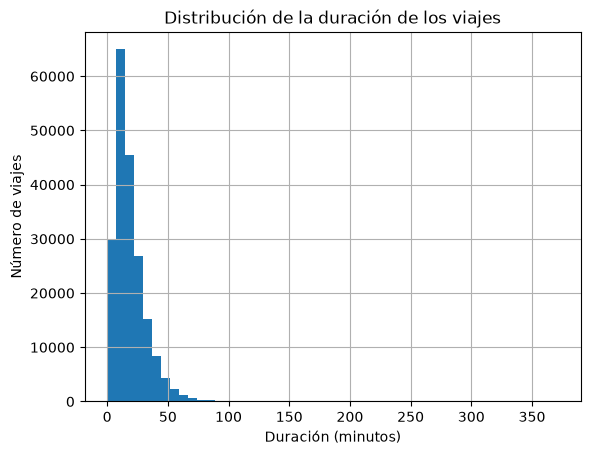

In [8]:
dfTaxis['duracion'].hist(bins=50)
plt.xlabel('Duración (minutos)')
plt.ylabel('Número de viajes')
plt.title('Distribución de la duración de los viajes')
plt.show()

In [9]:
# Viajes con duración igual o inferior a cero
dfTaxis[dfTaxis['duracion'] <= 0]

,hvfhs_license_num,dispatching_base_num,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,SR_Flag,duracion
183512,HV0005,B02510,2019-03-21 22:00:40,2019-03-21 22:00:40,217,217,NaN,0.0


In [10]:
taxisClean = dfTaxis[dfTaxis['duracion'] > 0]

### NOTAS Tratamiento de valores nulos y duración de los viajes

En primer lugar, se han comprobado los valores nulos de todas las columnas del dataset.

Se han detectado valores nulos en dos columnas:

- `dispatching_base_num`: presenta únicamente 3 valores nulos sobre 200.000 registros.
- `SR_Flag`: presenta 156.424 valores nulos.

Se ha decidido conservar estos registros sin realizar ninguna imputación ni eliminación, ya que ambas columnas no intervienen directamente en el análisis de las ubicaciones ni en el entrenamiento de nuestro modelo, que utilizará `PULocationID`, `DOLocationID` y la duración del viaje.

A continuación, se ha calculado la duración de cada trayecto mediante la diferencia entre la fecha de finalización y la fecha de recogida, expresándola en minutos.

Durante la comprobación de esta nueva variable se ha detectado un registro con duración de cero minutos, cuyas fechas de recogida y finalización eran exactamente iguales. Se ha considerado un registro no válido para el objetivo de predicción y se ha eliminado.

Por otra parte, se han conservado los viajes de duración elevada, ya que podrían corresponder a trayectos reales y no se dispone de información suficiente para considerarlos erróneos.

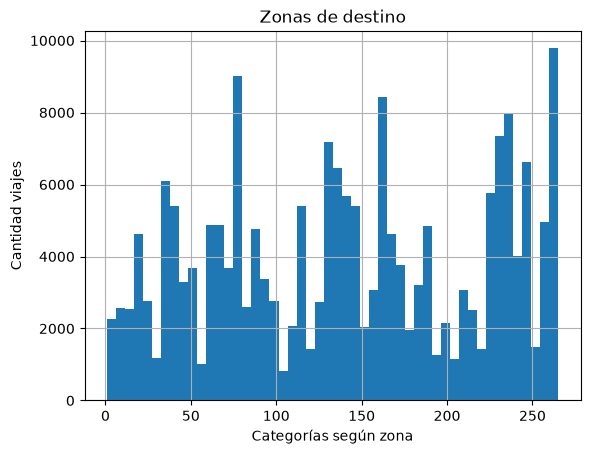

In [11]:
taxisClean['DOLocationID'].hist(bins=50)
#categoruias - localizaciones que tengan pocos viajes = localizaciones poco frecuentes
plt.title('Zonas de destino')
plt.xlabel('Categorías según zona')
plt.ylabel('Cantidad viajes')
plt.show()

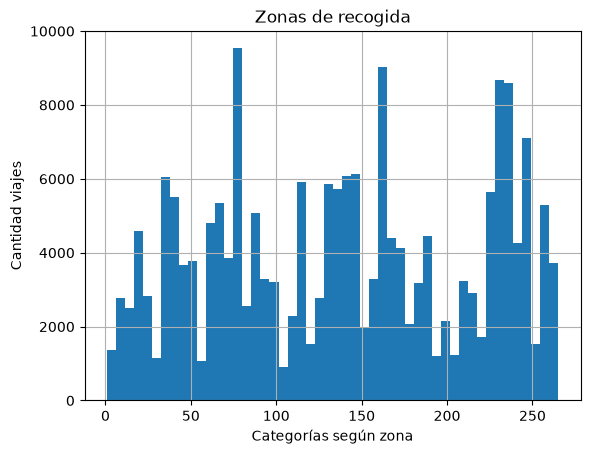

In [12]:
taxisClean['PULocationID'].hist(bins=50)
#categoruias - localizaciones que tengan pocos viajes = localizaciones poco frecuentes
plt.title('Zonas de recogida')
plt.xlabel('Categorías según zona')
plt.ylabel('Cantidad viajes')
plt.show()

In [13]:
taxisClean['PULocationID'].value_counts().describe()

count     260.000000
mean      769.226923
std       698.573499
min         1.000000
25%       214.250000
50%       527.500000
75%      1157.250000
max      3439.000000
Name: count, dtype: float64

In [14]:
taxisClean['DOLocationID'].value_counts().describe()

count     260.000000
mean      769.226923
std       771.788645
min         1.000000
25%       226.750000
50%       522.500000
75%      1136.750000
max      6282.000000
Name: count, dtype: float64

In [15]:
# Zonas que aparecen menos de 70 veces
print("Recogidas:")
print((taxisClean['PULocationID'].value_counts() < 70).sum())

print("Destinos:")
print((taxisClean['DOLocationID'].value_counts() < 70).sum())

Recogidas:
31
Destinos:
26


In [16]:
# Zonas que aparecen menos de 100 veces
print("Recogidas:")
print((taxisClean['PULocationID'].value_counts() < 100).sum())

print("Destinos:")
print((taxisClean['DOLocationID'].value_counts() <100).sum())


# Zonas que aparecen menos de 100 veces
# print("Recogidas:")
# zonas_recogida = (taxisClean['PULocationID'].value_counts() < 100).sum()
# print(zonas_recogida)
# print("Porcentaje:", round(zonas_recogida / 260 * 100, 2), "%")

# print("\nDestinos:")
# zonas_destino = (taxisClean['DOLocationID'].value_counts() < 100).sum()
# print(zonas_destino)
# print("Porcentaje:", round(zonas_destino / 260 * 100, 2), "%")

Recogidas:
37
Destinos:
34


In [17]:
# Zonas que aparecen menos de 150 veces
print("Recogidas:")
print((taxisClean['PULocationID'].value_counts() < 150).sum())

print("Destinos:")
print((taxisClean['DOLocationID'].value_counts() <150).sum())

Recogidas:
47
Destinos:
45


In [18]:
frecuencias_recogida = taxisClean['PULocationID'].value_counts()
frecuencias_destino = taxisClean['DOLocationID'].value_counts()

for umbral in [50, 100, 200]:
    print(f"\nUmbral: {umbral}")
    print("Recogidas:", (frecuencias_recogida < umbral).sum())
    print("Destinos:", (frecuencias_destino < umbral).sum())


Umbral: 50
Recogidas: 26
Destinos: 22

Umbral: 100
Recogidas: 37
Destinos: 34

Umbral: 200
Recogidas: 63
Destinos: 60


In [19]:
# Obtener la frecuencia de cada zona
frecuencias = taxisClean['PULocationID'].value_counts()

# Identificar las zonas con menos de 100 viajes
zonas_poco_frecuentes = frecuencias[frecuencias < 100].index

# Agruparlas en la categoría 0
taxisClean.loc[
    taxisClean['PULocationID'].isin(zonas_poco_frecuentes),
    'PULocationID'
] = 0

In [20]:
# Obtener la frecuencia de cada zona
frecuencias = taxisClean['DOLocationID'].value_counts()

# Identificar las zonas con menos de 100 viajes
zonas_poco_frecuentes = frecuencias[frecuencias < 100].index

# Agruparlas en la categoría 0
taxisClean.loc[
    taxisClean['DOLocationID'].isin(zonas_poco_frecuentes),
    'DOLocationID'
] = 0

In [21]:
print("Categorías de recogida:", taxisClean['PULocationID'].nunique())
print("Categorías de destino:", taxisClean['DOLocationID'].nunique())

print("\nFrecuencia de la categoría genérica:")
print("Recogidas:", (taxisClean['PULocationID'] == 0).sum())
print("Destinos:", (taxisClean['DOLocationID'] == 0).sum())

Categorías de recogida: 224
Categorías de destino: 227

Frecuencia de la categoría genérica:
Recogidas: 1369
Destinos: 1353


Tras analizar las frecuencias de las zonas, establecemos un umbral de 100 viajes para agrupar las categorías menos representadas.

En las zonas de recogida agrupamos 37 categorías (14,23 % de las categorías originales), mientras que en las zonas de destino agrupamos 34 (13,08 %).

Todas estas categorías pasan a identificarse mediante una categoría genérica (`0`). Como resultado, reducimos las categorías de 260 a 224 en recogidas y a 227 en destinos, sin eliminar ningún registro del conjunto de datos.

In [22]:
LabelEncRecogida=LabelEncoder()
taxisClean['PULocationID']=LabelEncRecogida.fit_transform(taxisClean['PULocationID'])
taxisClean.head()

,hvfhs_license_num,dispatching_base_num,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,SR_Flag,duracion
0,HV0005,B02510,2019-02-12 11:10:30,2019-02-12 11:19:14,65,112,NaN,8.733333
1,HV0005,B02510,2019-02-12 11:35:27,2019-02-12 11:54:29,216,125,NaN,19.033333
2,HV0003,B02867,2019-02-12 11:03:14,2019-02-12 11:21:04,172,155,1.0,17.833333
3,HV0003,B02867,2019-02-12 11:12:12,2019-02-12 11:24:40,127,155,1.0,12.466667
4,HV0003,B02867,2019-02-12 11:50:05,2019-02-12 11:59:14,127,91,NaN,9.150000


In [23]:
LabelEncDestino=LabelEncoder()
taxisClean['DOLocationID']=LabelEncDestino.fit_transform(taxisClean['DOLocationID'])
taxisClean.head()

,hvfhs_license_num,dispatching_base_num,pickup_datetime,dropoff_datetime,PULocationID,DOLocationID,SR_Flag,duracion
0,HV0005,B02510,2019-02-12 11:10:30,2019-02-12 11:19:14,65,88,NaN,8.733333
1,HV0005,B02510,2019-02-12 11:35:27,2019-02-12 11:54:29,216,100,NaN,19.033333
2,HV0003,B02867,2019-02-12 11:03:14,2019-02-12 11:21:04,172,128,1.0,17.833333
3,HV0003,B02867,2019-02-12 11:12:12,2019-02-12 11:24:40,127,128,1.0,12.466667
4,HV0003,B02867,2019-02-12 11:50:05,2019-02-12 11:59:14,127,76,NaN,9.150000


In [24]:
nCategoriasPickup = taxisClean['PULocationID'].nunique()
nCategoriasDropoff = taxisClean['DOLocationID'].nunique()

print("Categorías de recogida:", nCategoriasPickup)
print("Categorías de destino:", nCategoriasDropoff)

#Primero aprende las categorías y después las transforma.
#si tenemos 260 categorías de recogida, la capa podrá disponer de 260 vectores, uno para cada índice entre 0 y 260
# trasnforma cada categoría en un número entero consecutivo, desde 0 hasta el máximo índice.

Categorías de recogida: 224
Categorías de destino: 227


In [25]:
XPU=taxisClean['PULocationID']
XDO=taxisClean['DOLocationID']
yduracion=taxisClean['duracion'] #target

In [26]:
nCategoriasRecogida=taxisClean[['PULocationID']].value_counts().shape[0]
nCategoriasDestino=taxisClean[['DOLocationID']].value_counts().shape[0]


In [27]:
#PuLocation
modelRecogida = Sequential()
outputRecogida = int(1.6 * nCategoriasRecogida**0.25)

modelRecogida.add(Embedding(input_dim=nCategoriasRecogida, output_dim=outputRecogida, input_length=1, name="recogida_embedding"))

modelRecogida.add(Flatten())

modelRecogida.add(Dense(32, activation='relu'))
modelRecogida.add(Dropout(0.3))
modelRecogida.add(Dense(1, activation='relu'))

modelRecogida.compile(optimizer='adam',loss='mean_absolute_error', metrics=['mae'])
modelRecogida.summary()
# El modelo intentará predecir el 1 o 0. Para hacerlo, ajustará los pesos del Embedding.

modelRecogida.fit(XPU, yduracion, verbose=1,batch_size=64,
    epochs=4)


/home/pabilion/proyecto-taxis/.venv/lib/python3.14/site-packages/keras/src/layers/core/embedding.py:104: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(
E0000 00:00:1795422162.100290    1245 cuda_executor.cc:1690] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:68

W0000 00:00:1795422162.101827    1347 cuda_executor.cc:1710] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:77
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:107
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:112

W0000 00:00:1795422162.218681    1245 

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ recogida_embedding (Embedding)  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/4
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 20s 5ms/step - loss: 9.6838 - mae: 9.6838
Epoch 2/4
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 14s 4ms/step - loss: 9.0890 - mae: 9.0890
Epoch 3/4
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 14s 4ms/step - loss: 9.0637 - mae: 9.0637
Epoch 4/4
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - loss: 9.0524 - mae: 9.0524


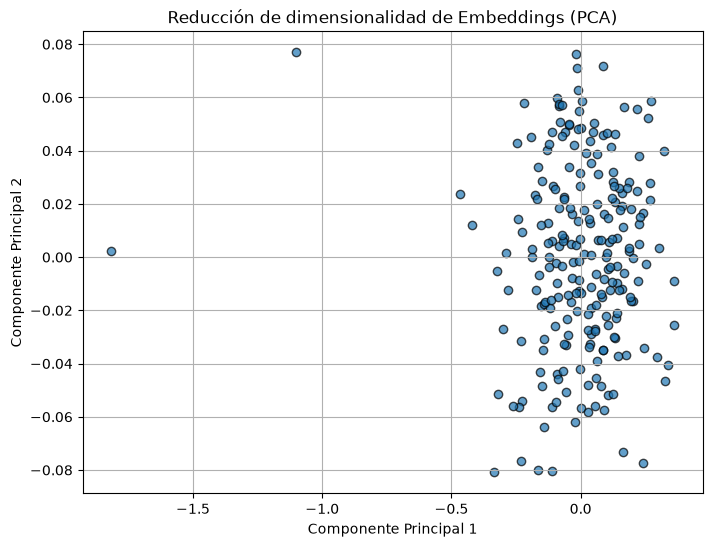

In [28]:
#Vamos a realizar una reduccion de dimensionalidad para representar los embeddings anteriores en 2 dimensiones, partiendo de los embeddings de la red neuronal

from sklearn.decomposition import PCA

embsRecogida= modelRecogida.get_layer('recogida_embedding').get_weights()[0]

pca_embeddings_recogida = PCA(n_components=2).fit_transform(embsRecogida)


plt.figure(figsize=(8, 6))
plt.scatter(pca_embeddings_recogida[:, 0], pca_embeddings_recogida[:, 1], alpha=0.7, edgecolors='k')

plt.title('Reducción de dimensionalidad de Embeddings (PCA)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True)
plt.show()

In [ ]:
# Zona 132 (índice 105). a estudiar 
# Zona 138 (índice 111).
indices = np.where(pca_embeddings_recogida[:, 0] < -1.0)[0]
indicesOriginales= LabelEncRecogida.classes_[indices]

In [65]:

indicesOriginales132=indicesOriginales[0]
datos_zona132 = taxisClean[taxisClean['PULocationID'] == indices[0]]
mediaTiempo=datos_zona132['duracion'].mean()
maxTiempo=datos_zona132['duracion'].max()
print("Zona original:", indicesOriginales132)
print(f"media : {mediaTiempo}, máxima : {maxTiempo}")
# indicesOriginales138=indicesOriginales[1]
datos_zona132['duracion'].describe()

# for indice in indices:
#     print("Índice:", indice)
#     print("Zona original:", LabelEncRecogida.classes_[indice]) #recupera el identificador original de esa categoría antes de codificarla con LabelEncoder


# for indice in indices:
#     zona = LabelEncRecogida.classes_[indice]
#     datos_zona = taxisClean[taxisClean['PULocationID'] == indice]
#     # print(datos_zona)
#     print("\nÍndice:", indice)
#     print("Zona original:", zona)
#     print("Número de trayectos:", len(datos_zona))
#     print("Duración media:", datos_zona['duracion'].mean())
#     print("Duración mediana:", datos_zona['duracion'].median())

Zona original: 132
media : 41.726085547634476, máxima : 164.85


count    3086.000000
mean       41.726086
std        19.755993
min         0.066667
25%        29.320833
50%        39.983333
75%        52.504167
max       164.850000
Name: duracion, dtype: float64

In [ ]:
# datos_zona138 = taxisClean[taxisClean['PULocationID'] == indices[1]]

# datos_zona138['duracion'].describe()

count    2682.000000
mean       32.740685
std        14.165612
min         0.050000
25%        22.683333
50%        30.700000
75%        40.691667
max       139.650000
Name: duracion, dtype: float64

In [66]:
print("Media general:", taxisClean['duracion'].mean())
print("Media zona 132:", datos_zona132['duracion'].mean())
# print("Media zona 138:", datos_zona138['duracion'].mean())

Media general: 18.842325878296055
Media zona 132: 41.726085547634476


In [67]:
print("Mínimo general:", taxisClean['duracion'].min())
print("Mínimo zona 132:", datos_zona132['duracion'].min())
# print("Mínimo zona 138:", datos_zona138['duracion'].min())

Mínimo general: 0.016666666666666666
Mínimo zona 132: 0.06666666666666667


In [68]:
print("máximo general:", taxisClean['duracion'].max())
print("máximo zona 132:", datos_zona132['duracion'].max())
# print("máximo zona 138:", datos_zona138['duracion'].max())

máximo general: 371.46666666666664
máximo zona 132: 164.85


<Axes: >

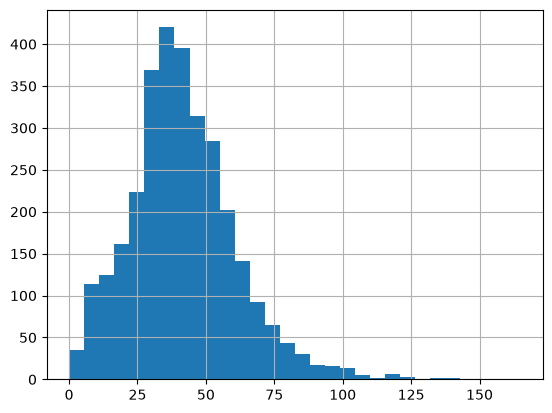

In [58]:
datos_zona132['duracion'].hist(bins=30)

<Axes: >

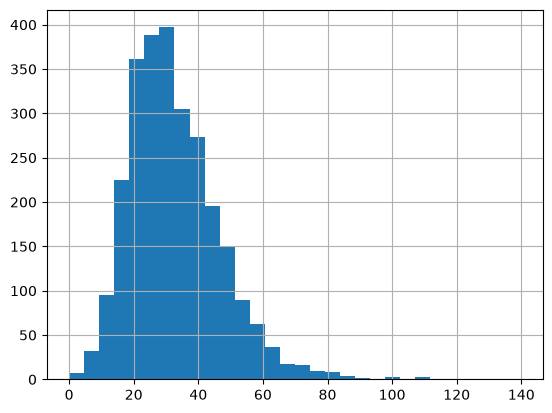

In [ ]:
# datos_zona138['duracion'].hist(bins=30)

<Axes: >

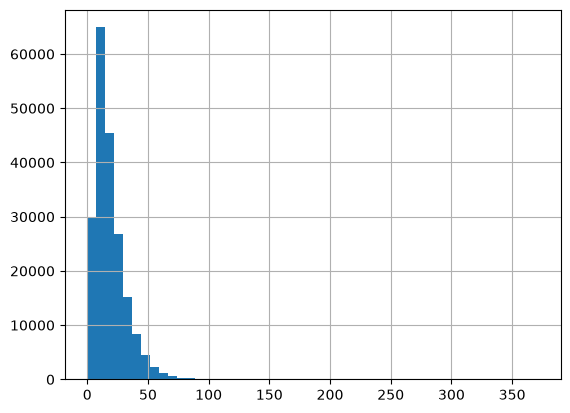

In [63]:
taxisClean['duracion'].hist(bins=50)

In [69]:
print("Zona 132:")
print(datos_zona132['duracion'].quantile([0.25, 0.50, 0.75]))

# print("\nZona 138:")
# print(datos_zona138['duracion'].quantile([0.25, 0.50, 0.75]))

print("\nTodos los trayectos:")
print(taxisClean['duracion'].quantile([0.25, 0.50, 0.75]))

Zona 132:
0.25    29.320833
0.50    39.983333
0.75    52.504167
Name: duracion, dtype: float64

Todos los trayectos:
0.25     9.600000
0.50    15.533333
0.75    24.550000
Name: duracion, dtype: float64


In [70]:
print("Todos los trayectos:")
print((taxisClean['duracion'] > 30).mean() * 100)

print("Zona 132:")
print((datos_zona132['duracion'] > 30).mean() * 100)

# print("Zona 138:")
# print((datos_zona138['duracion'] > 30).mean() * 100)

Todos los trayectos:
16.072080360401802
Zona 132:
73.39598185353208


In [71]:
print("Todos los trayectos:")
print((taxisClean['duracion'] > 60).mean() * 100)

print("Zona 132:")
print((datos_zona132['duracion'] > 60).mean() * 100)

# print("Zona 138:")
# print((datos_zona138['duracion'] > 60).mean() * 100)

Todos los trayectos:
1.2400062000310001
Zona 132:
14.711600777705769


In [30]:
#DOLocation
model = Sequential()
output = int(1.6 * nCategoriasDestino**0.25)

model.add(Embedding(input_dim=nCategoriasDestino, output_dim=output, input_length=1, name="destino_embedding"))

model.add(Flatten())

model.add(Dense(32, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(1, activation='relu'))

model.compile(optimizer='adam',loss='mean_absolute_error', metrics=['mae'])
model.summary()
# El modelo intentará predecir el 1 o 0. Para hacerlo, ajustará los pesos del Embedding.

model.fit(XDO, yduracion, verbose=1,batch_size=64,
    epochs=4)

/home/pabilion/proyecto-taxis/.venv/lib/python3.14/site-packages/keras/src/layers/core/embedding.py:104: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ destino_embedding (Embedding)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/4
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 17s 5ms/step - loss: 9.3699 - mae: 9.3699
Epoch 2/4
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 14s 5ms/step - loss: 8.7976 - mae: 8.7976
Epoch 3/4
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 14s 4ms/step - loss: 8.7850 - mae: 8.7850
Epoch 4/4
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - loss: 8.7777 - mae: 8.7777


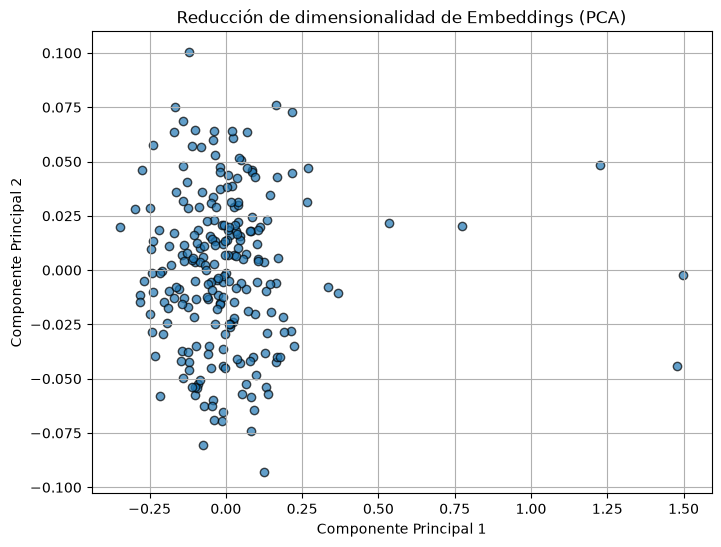

In [31]:
from sklearn.decomposition import PCA

embsdestino= model.get_layer('destino_embedding').get_weights()[0]

pca_embeddings = PCA(n_components=2).fit_transform(embsdestino)


plt.figure(figsize=(8, 6))
plt.scatter(pca_embeddings[:, 0], pca_embeddings[:, 1], alpha=0.7, edgecolors='k')

plt.title('Reducción de dimensionalidad de Embeddings (PCA)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True)
plt.show()

In [78]:
indices = np.where(pca_embeddings[:, 0] > 1.25)[0]
indicesOriginales= LabelEncDestino.classes_[indices]
indicesOriginalesDestinoestudiar=indicesOriginales[0]
indicesOriginales
# for indice in indices:
#     print("Índice:", indice)
#     print("Zona original:", LabelEncDestino.classes_[indice])

array([  1, 132])

In [80]:
datos_zona1 = taxisClean[taxisClean['DOLocationID'] == indices[0]]

datos_zona1['duracion'].describe()

count    1084.000000
mean       40.135347
std        12.576013
min        17.883333
25%        31.283333
50%        37.508333
75%        46.558333
max       136.566667
Name: duracion, dtype: float64

In [81]:
print("Todos los trayectos:")
print((taxisClean['duracion'] > 30).mean() * 100)

print("Destino zona 1:")
print((datos_zona1['duracion'] > 30).mean() * 100)


Todos los trayectos:
16.072080360401802
Destino zona 1:
80.81180811808119


In [82]:
print("Todos los trayectos:")
print((taxisClean['duracion'] > 60).mean() * 100)

print("Destino zona 1:")
print((datos_zona1['duracion'] > 60).mean() * 100)

Todos los trayectos:
1.2400062000310001
Destino zona 1:
7.011070110701106


In [83]:
print("Media general:", taxisClean['duracion'].mean())
print("Media destino 1:", datos_zona1['duracion'].mean())

print("\nMínimo general:", taxisClean['duracion'].min())
print("Mínimo destino 1:", datos_zona1['duracion'].min())

print("\nMáximo general:", taxisClean['duracion'].max())
print("Máximo destino 1:", datos_zona1['duracion'].max())

Media general: 18.842325878296055
Media destino 1: 40.135347478474785

Mínimo general: 0.016666666666666666
Mínimo destino 1: 17.883333333333333

Máximo general: 371.46666666666664
Máximo destino 1: 136.56666666666666


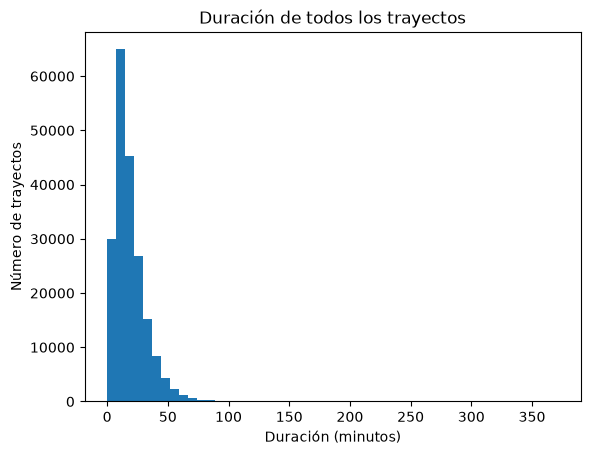

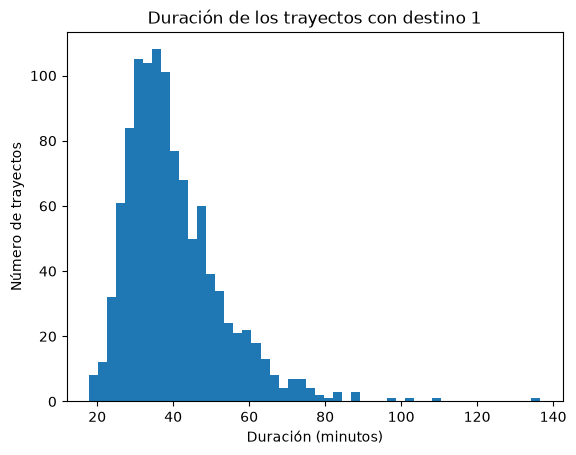

In [86]:
import matplotlib.pyplot as plt

plt.hist(taxisClean['duracion'], bins=50)
plt.title("Duración de todos los trayectos")
plt.xlabel("Duración (minutos)")
plt.ylabel("Número de trayectos")
plt.show()

plt.hist(datos_zona1['duracion'], bins=50)
plt.title("Duración de los trayectos con destino 1")
plt.xlabel("Duración (minutos)")
plt.ylabel("Número de trayectos")
plt.show()